# Examen Módulo 3 — Evaluación de modelos con datos desbalanceados
## Detección de fallas industriales

**Alumno:** Christian Dzul  
**Matrícula:** 17003832 

**Objetivo.** Predecir si un componente industrial fallará en las próximas 24 horas a partir de 12 lecturas de sensores. Solo ~3 % de los casos son fallas, así que el reto no es solo entrenar un modelo, sino **medirlo bien** y **tratar el desbalance**.

**Cómo está organizado el notebook**

| Sección | Contenido |
|---|---|
| 0 | Librerías y versiones |
| 1 | Preparación de los datos y grado de desbalance |
| 2 | Modelo base (regresión logística sin tratar el desbalance) |
| 3 | Cuatro estrategias contra el desbalance |
| 4 | Tabla comparativa y recomendación |
| 5 | Calibración de probabilidades |

**Metodología (igual para las 5 configuraciones):**
- **Etapa 1 – Validación cruzada:** 5 particiones estratificadas sobre el entrenamiento (4,800 filas), con MCC como métrica; se reporta media ± desviación estándar.
- **Etapa 2 – Prueba:** se entrena con todo el entrenamiento y se evalúa **una sola vez** en la prueba (1,200 filas): exactitud, MCC y kappa.

## 0. Librerías y versiones

In [1]:
import sys, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import imblearn

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, matthews_corrcoef, cohen_kappa_score, make_scorer,
                             confusion_matrix, ConfusionMatrixDisplay, brier_score_loss)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

from imblearn.pipeline import Pipeline            # Pipeline que permite remuestrear dentro de la validación cruzada
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 160)

pd.DataFrame({"versión": {
    "Python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__, "scikit-learn": sklearn.__version__,
    "imbalanced-learn": imblearn.__version__}})

,versión
Python,3.13.16
numpy,2.5.4
pandas,3.1.1
matplotlib,3.11.2
scikit-learn,1.9.1
imbalanced-learn,0.14.2


## 1. Preparación de los datos

El dataset se genera con el código indicado en el enunciado (mismo `random_state=42`) y se divide 80/20 de forma **estratificada**, para que entrenamiento y prueba conserven la misma proporción de fallas.

In [2]:
X, y = make_classification(
    n_samples=6000, n_features=12, n_informative=6, n_redundant=2,
    n_repeated=0, n_clusters_per_class=2, weights=[0.97, 0.03],
    flip_y=0.01, class_sep=0.9, random_state=42)

columnas = [f"sensor_{i}" for i in range(1, 13)]
df = pd.DataFrame(X, columns=columnas)
df["falla"] = y

X = df[columnas]
y = df["falla"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

print("Dataset completo:", df.shape, "  Entrenamiento:", X_train.shape, "  Prueba:", X_test.shape)
df.head()

Dataset completo: (6000, 13)   Entrenamiento: (4800, 12)   Prueba: (1200, 12)


,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,falla
0,0.738767,0.360155,-1.106954,-0.563810,-2.131640,1.008782,-0.820798,-0.475143,-0.367828,0.841062,1.097829,0.717722,0
1,0.911091,-2.016704,-2.323291,0.009165,-2.722033,-0.340034,-0.428739,-0.654519,0.409324,0.391071,1.958482,-1.346447,0
2,2.223053,-0.725349,-3.428513,0.067925,-4.103644,-2.673319,0.601297,0.297512,-1.650981,-0.703855,2.576378,0.290889,0
3,-0.316375,0.932780,-0.350469,0.747246,1.095914,-0.447414,-0.129707,-0.470575,-1.952282,-1.512581,0.802544,-1.270026,0
4,0.728786,0.326235,-0.644380,0.789678,1.343746,-0.372035,-0.583101,-2.256378,1.443619,-2.242116,-0.699013,0.599397,0


               sin falla (0)  falla (1)  % falla  razón 0:1
conjunto                                                   
Completo                5799        201     3.35       28.9
Entrenamiento           4639        161     3.35       28.8
Prueba                  1160         40     3.33       29.0


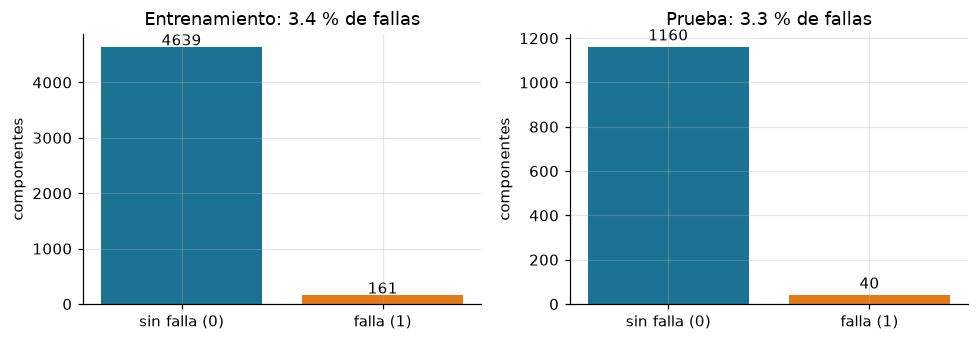

In [3]:
desbalance = pd.DataFrame({
    "conjunto": ["Completo", "Entrenamiento", "Prueba"],
    "sin falla (0)": [(y == 0).sum(), (y_train == 0).sum(), (y_test == 0).sum()],
    "falla (1)": [(y == 1).sum(), (y_train == 1).sum(), (y_test == 1).sum()],
}).set_index("conjunto")
desbalance["% falla"] = (100 * desbalance["falla (1)"] / desbalance.sum(axis=1)).round(2)
desbalance["razón 0:1"] = (desbalance["sin falla (0)"] / desbalance["falla (1)"]).round(1)
print(desbalance.to_string())

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for ax, (nombre, serie) in zip(axes, [("Entrenamiento", y_train), ("Prueba", y_test)]):
    conteo = serie.value_counts().sort_index()
    ax.bar(["sin falla (0)", "falla (1)"], conteo.values, color=["#1C7293", "#E07A1F"])
    for i, v in enumerate(conteo.values):
        ax.text(i, v + 30, str(v), ha="center")
    ax.set_title(f"{nombre}: {100 * serie.mean():.1f} % de fallas"); ax.set_ylabel("componentes")
plt.tight_layout(); plt.show()

**Grado de desbalance.** El desbalance es fuerte: de 6,000 componentes solo 201 fallan (3.35 %), es decir, hay unos **29 componentes sanos por cada falla**. Gracias a la estratificación, el entrenamiento tiene 161 fallas y la prueba 40, ambos con la misma proporción (3.35 %). Que la prueba tenga solo 40 fallas es importante para leer los resultados: acertar o fallar en uno o dos de esos casos ya mueve las métricas de forma notable.

### Protocolo común de evaluación

Todas las configuraciones usan **la misma regresión logística** (`max_iter=1000`, `random_state=42` y el resto de valores por defecto) dentro de un `Pipeline` de *imbalanced-learn*: **escalar → (remuestrear) → regresión logística**. Usar este `Pipeline` es clave: en la validación cruzada, el remuestreo se aplica **solo a las particiones de entrenamiento**, y la partición de validación se queda con su proporción real de fallas. Si se remuestreara antes de dividir, copias o versiones sintéticas de una misma falla terminarían en entrenamiento y validación a la vez, y el MCC saldría artificialmente alto.

La función `evalua` aplica las dos etapas de la metodología y devuelve los resultados de cada configuración.

In [4]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
mcc_scorer = make_scorer(matthews_corrcoef)
resultados = {}      # resumen de cada configuración
modelos = {}         # cada configuración entrenada con todo el entrenamiento


def regresion_logistica(**extra):
    # Mismos hiperparámetros para las 5 configuraciones (solo cambia lo indicado en cada estrategia)
    return LogisticRegression(max_iter=1000, random_state=42, **extra)


def evalua(nombre, modelo):
    # Etapa 1: validación cruzada estratificada de 5 particiones sobre el entrenamiento (MCC)
    mcc_cv = cross_val_score(modelo, X_train, y_train, cv=kf, scoring=mcc_scorer)
    # Etapa 2: entrenar con todo el entrenamiento y evaluar UNA vez en la prueba
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    vn, fp, fn, vp = confusion_matrix(y_test, pred).ravel()
    resultados[nombre] = {"MCC_CV_media": mcc_cv.mean(), "MCC_CV_desv": mcc_cv.std(),
                          "exactitud_prueba": accuracy_score(y_test, pred),
                          "MCC_prueba": matthews_corrcoef(y_test, pred),
                          "kappa_prueba": cohen_kappa_score(y_test, pred),
                          "fallas_detectadas": f"{vp} de {vp + fn}", "falsas_alarmas": fp}
    modelos[nombre] = modelo
    r = resultados[nombre]
    print(f"Etapa 1 · Validación cruzada (5 particiones): MCC = {r['MCC_CV_media']:.3f} ± {r['MCC_CV_desv']:.3f}"
          f"   (por partición: {np.round(mcc_cv, 3)})")
    print(f"Etapa 2 · Prueba: exactitud = {r['exactitud_prueba']:.3f} | MCC = {r['MCC_prueba']:.3f} | "
          f"kappa = {r['kappa_prueba']:.3f} | fallas detectadas: {vp} de {vp + fn} | falsas alarmas: {fp}")
    return pred


def matriz(pred, titulo):
    fig, ax = plt.subplots(figsize=(3.6, 3.2))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["sin falla", "falla"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(titulo, fontsize=9); ax.grid(False); plt.tight_layout(); plt.show()

## 2. Modelo base

Regresión logística sobre los datos escalados con `StandardScaler`, **sin ningún tratamiento del desbalance**. Como referencia, también se calcula la exactitud de un modelo trivial que **siempre predice «sin falla»**.

Etapa 1 · Validación cruzada (5 particiones): MCC = 0.140 ± 0.076   (por partición: [0.119 0.206 0.038 0.246 0.092])
Etapa 2 · Prueba: exactitud = 0.966 | MCC = 0.169 | kappa = 0.119 | fallas detectadas: 3 de 40 | falsas alarmas: 4


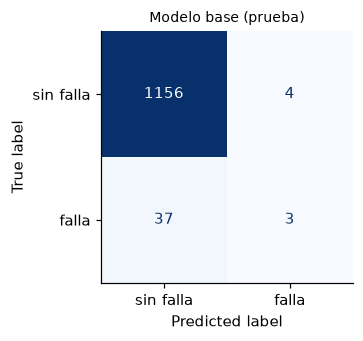

Modelo trivial («nunca hay falla»): exactitud = 0.967 | MCC = 0.000 | kappa = 0.000


In [5]:
base = Pipeline([("escalado", StandardScaler()), ("modelo", regresion_logistica())])
pred_base = evalua("Modelo base", base)
matriz(pred_base, "Modelo base (prueba)")

trivial = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred_trivial = trivial.predict(X_test)
print(f"Modelo trivial («nunca hay falla»): exactitud = {accuracy_score(y_test, pred_trivial):.3f} | "
      f"MCC = {matthews_corrcoef(y_test, pred_trivial):.3f} | kappa = {cohen_kappa_score(y_test, pred_trivial):.3f}")

**¿Por qué la exactitud es poco informativa en este problema?**

A primera vista, el modelo base parece excelente: acierta el **96.6 %** de los casos. Pero la matriz de confusión cuenta otra historia: de las **40 fallas** de la prueba solo detecta **3**; las otras 37 pasan inadvertidas. Como el 96.7 % de los componentes no falla, un modelo puede tener una exactitud altísima simplemente diciendo «no hay falla» casi siempre. De hecho, el modelo trivial que **nunca** predice falla obtiene una exactitud de **96.7 %**, un poco más que el modelo base, aun siendo completamente inútil para el objetivo del problema.

Por eso la exactitud no sirve aquí: está dominada por la clase mayoritaria y casi no cambia aunque el modelo ignore las fallas. El **MCC** y el **kappa de Cohen** sí lo notan, porque consideran los cuatro tipos de aciertos y errores y descuentan lo que se acertaría por azar: el modelo trivial obtiene 0 en ambos, y el modelo base apenas **0.169** (MCC) y **0.119** (kappa), valores bajos que reflejan que casi no detecta fallas. En validación cruzada el MCC es **0.140 ± 0.076**: además de bajo, varía mucho entre particiones, porque depende de unas pocas fallas acertadas.

## 3. Cuatro estrategias contra el desbalance

Las cuatro estrategias buscan lo mismo: que el modelo **le dé más importancia a las fallas** durante el entrenamiento. Tres lo logran cambiando los datos de entrenamiento (remuestreo) y una cambiando cómo se castigan los errores. La regresión logística es la misma en todos los casos.

La siguiente celda muestra cómo queda el conjunto de entrenamiento después de cada técnica de remuestreo (solo como ilustración; en la evaluación, el remuestreo ocurre dentro del `Pipeline`).

In [6]:
X_train_esc = StandardScaler().fit_transform(X_train)
efecto = {"Original": np.bincount(y_train)}
for nombre, muestreador in [("Sobremuestreo", RandomOverSampler(random_state=42)),
                            ("Submuestreo", RandomUnderSampler(random_state=42)),
                            ("SMOTE", SMOTE(random_state=42))]:
    _, y_res = muestreador.fit_resample(X_train_esc, y_train)
    efecto[nombre] = np.bincount(y_res)
efecto = pd.DataFrame(efecto, index=["sin falla (0)", "falla (1)"]).T
efecto["total"] = efecto.sum(axis=1)
efecto

,sin falla (0),falla (1),total
Original,4639,161,4800
Sobremuestreo,4639,4639,9278
Submuestreo,161,161,322
SMOTE,4639,4639,9278


### 3.1 Sobremuestreo aleatorio (`RandomOverSampler`)

**Qué hace:** copia al azar casos de falla hasta que haya tantas fallas como componentes sanos (4,639 de cada clase en el entrenamiento). No inventa información nueva; solo repite la que ya existe para que el modelo no la ignore.

Etapa 1 · Validación cruzada (5 particiones): MCC = 0.224 ± 0.029   (por partición: [0.259 0.176 0.21  0.245 0.231])
Etapa 2 · Prueba: exactitud = 0.785 | MCC = 0.257 | kappa = 0.154 | fallas detectadas: 33 de 40 | falsas alarmas: 251


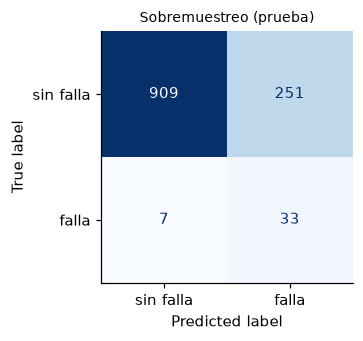

In [7]:
sobremuestreo = Pipeline([("escalado", StandardScaler()),
                          ("remuestreo", RandomOverSampler(random_state=42)),
                          ("modelo", regresion_logistica())])
pred_ros = evalua("Sobremuestreo", sobremuestreo)
matriz(pred_ros, "Sobremuestreo (prueba)")

**Resultado.** El cambio es claro: el modelo pasa de detectar 3 a detectar **33 de las 40 fallas**. A cambio, genera **251 falsas alarmas** (componentes sanos marcados como falla), por lo que la exactitud baja a **78.5 %**. Aun así, el MCC sube de 0.169 a **0.257** y el kappa de 0.119 a **0.154**: el modelo es más útil, aunque menos «exacto». En validación cruzada, el MCC sube de 0.140 a **0.224** y, sobre todo, se vuelve mucho más estable (desviación de 0.029 frente a 0.076).

### 3.2 Submuestreo aleatorio (`RandomUnderSampler`)

**Qué hace:** elimina al azar componentes sanos hasta igualar el número de fallas. El modelo termina entrenando con solo **322 casos** (161 de cada clase) en lugar de 4,800. Es rápido, pero desecha más del 90 % de los datos.

Etapa 1 · Validación cruzada (5 particiones): MCC = 0.227 ± 0.029   (por partición: [0.265 0.216 0.181 0.249 0.226])
Etapa 2 · Prueba: exactitud = 0.770 | MCC = 0.245 | kappa = 0.143 | fallas detectadas: 33 de 40 | falsas alarmas: 269


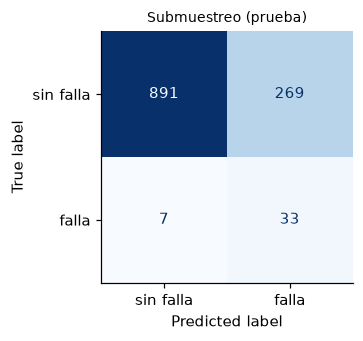

In [8]:
submuestreo = Pipeline([("escalado", StandardScaler()),
                        ("remuestreo", RandomUnderSampler(random_state=42)),
                        ("modelo", regresion_logistica())])
pred_rus = evalua("Submuestreo", submuestreo)
matriz(pred_rus, "Submuestreo (prueba)")

**Resultado.** Detecta las mismas **33 fallas** que el sobremuestreo, pero con algunas falsas alarmas más (**269**), por lo que su exactitud (77.0 %), su MCC (**0.245**) y su kappa (**0.143**) en prueba quedan ligeramente por debajo. En validación cruzada obtiene **0.227 ± 0.029**, prácticamente igual a las demás estrategias. Que funcione casi igual de bien aun tirando la mayoría de los datos sugiere que los componentes sanos son bastante parecidos entre sí; aun así, depender de tan pocos casos lo hace más sensible a qué filas se descartaron al azar.

### 3.3 SMOTE

**Qué hace:** en lugar de copiar fallas, **crea fallas sintéticas nuevas**: toma una falla real, elige otra falla parecida (vecina) y genera un punto intermedio entre ambas. Así el modelo ve más variedad de fallas sin repetir exactamente las mismas. Como mide distancias entre casos, se aplica después del escalado.

Etapa 1 · Validación cruzada (5 particiones): MCC = 0.223 ± 0.029   (por partición: [0.251 0.193 0.185 0.252 0.235])
Etapa 2 · Prueba: exactitud = 0.800 | MCC = 0.260 | kappa = 0.162 | fallas detectadas: 32 de 40 | falsas alarmas: 232


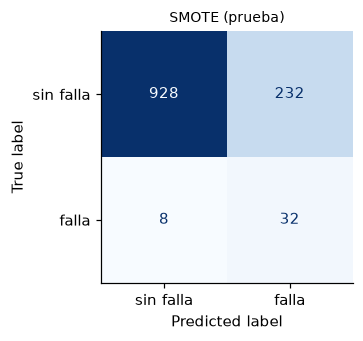

In [9]:
smote = Pipeline([("escalado", StandardScaler()),
                  ("remuestreo", SMOTE(random_state=42)),
                  ("modelo", regresion_logistica())])
pred_smote = evalua("SMOTE", smote)
matriz(pred_smote, "SMOTE (prueba)")

**Resultado.** SMOTE obtiene el **mejor resultado en la prueba**: MCC de **0.260** y kappa de **0.162**. Detecta **32 de las 40 fallas** (una menos que el sobremuestreo) pero con menos falsas alarmas (**232**), y por eso su exactitud también es la más alta de las cuatro estrategias (80.0 %). En validación cruzada, en cambio, queda empatado con las demás: **0.223 ± 0.029**.

### 3.4 Pesos de clase (`class_weight="balanced"`)

**Qué hace:** no toca los datos. Le indica a la regresión logística que **cada error en una falla cuente mucho más** que un error en un componente sano, en proporción inversa a su frecuencia: aquí, cada falla pesa unas 29 veces más. El efecto es parecido a tener tantas fallas como casos sanos, pero sin copiar ni crear filas.

Etapa 1 · Validación cruzada (5 particiones): MCC = 0.228 ± 0.029   (por partición: [0.27  0.187 0.206 0.248 0.231])
Etapa 2 · Prueba: exactitud = 0.784 | MCC = 0.247 | kappa = 0.148 | fallas detectadas: 32 de 40 | falsas alarmas: 251


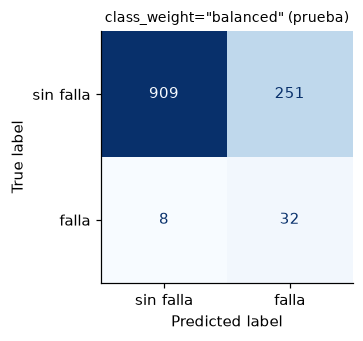

In [10]:
pesos = Pipeline([("escalado", StandardScaler()),
                  ("modelo", regresion_logistica(class_weight="balanced"))])
pred_bal = evalua('class_weight="balanced"', pesos)
matriz(pred_bal, 'class_weight="balanced" (prueba)')

**Resultado.** Se comporta casi igual que el sobremuestreo: **32 fallas detectadas** y **251 falsas alarmas**, con MCC de **0.247** y kappa de **0.148** en prueba. En validación cruzada obtiene el MCC medio más alto de todas las configuraciones, **0.228 ± 0.029**, aunque por un margen mínimo. Tiene sentido que se parezca tanto al sobremuestreo: repetir cada falla 29 veces y darle a cada falla un peso de 29 son, en la práctica, dos formas de decirle lo mismo al modelo.

## 4. Comparación de resultados

In [11]:
tabla = pd.DataFrame(resultados).T
cols_num = ["MCC_CV_media", "MCC_CV_desv", "exactitud_prueba", "MCC_prueba", "kappa_prueba"]
tabla[cols_num] = tabla[cols_num].astype(float).round(3)
tabla["MCC_CV (media ± desv.)"] = [f"{m:.3f} ± {d:.3f}" for m, d in zip(tabla["MCC_CV_media"], tabla["MCC_CV_desv"])]
tabla_comparativa = tabla[["MCC_CV (media ± desv.)", "exactitud_prueba", "MCC_prueba", "kappa_prueba",
                           "fallas_detectadas", "falsas_alarmas"]]
tabla_comparativa

,MCC_CV (media ± desv.),exactitud_prueba,MCC_prueba,kappa_prueba,fallas_detectadas,falsas_alarmas
Modelo base,0.140 ± 0.076,0.966,0.169,0.119,3 de 40,4
Sobremuestreo,0.224 ± 0.029,0.785,0.257,0.154,33 de 40,251
Submuestreo,0.227 ± 0.029,0.770,0.245,0.143,33 de 40,269
SMOTE,0.223 ± 0.029,0.800,0.260,0.162,32 de 40,232
"class_weight=""balanced""",0.228 ± 0.029,0.784,0.247,0.148,32 de 40,251


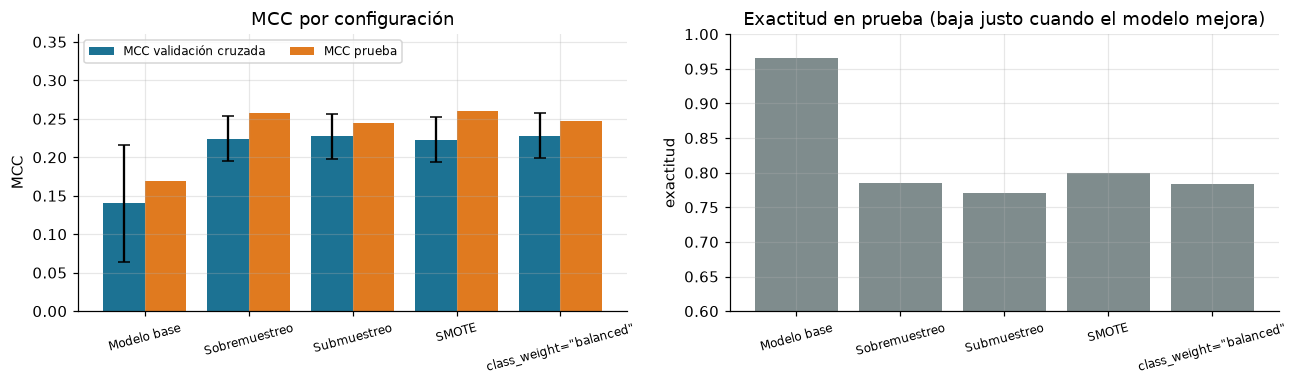

In [12]:
nombres = list(resultados)
x = np.arange(len(nombres))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(x - 0.2, tabla["MCC_CV_media"], 0.4, yerr=tabla["MCC_CV_desv"], capsize=4, label="MCC validación cruzada", color="#1C7293")
axes[0].bar(x + 0.2, tabla["MCC_prueba"], 0.4, label="MCC prueba", color="#E07A1F")
axes[0].set_xticks(x); axes[0].set_xticklabels(nombres, rotation=15, fontsize=8); axes[0].set_ylabel("MCC"); axes[0].set_ylim(0, 0.36); axes[0].legend(fontsize=8, loc="upper left", ncol=2)
axes[0].set_title("MCC por configuración")
axes[1].bar(x, tabla["exactitud_prueba"], color="#7F8C8D")
axes[1].set_xticks(x); axes[1].set_xticklabels(nombres, rotation=15, fontsize=8); axes[1].set_ylim(0.6, 1)
axes[1].set_ylabel("exactitud"); axes[1].set_title("Exactitud en prueba (baja justo cuando el modelo mejora)")
plt.tight_layout(); plt.show()

**Lectura de la tabla.** Las cuatro estrategias mejoran claramente al modelo base: el MCC de prueba sube de 0.169 a entre **0.245 y 0.260**, y el de validación cruzada de 0.140 a alrededor de **0.225**, con mucha menos variación entre particiones. El precio es una exactitud menor (de 96.6 % a cerca de 78–80 %), porque ahora el modelo se arriesga a marcar fallas y comete falsas alarmas. Esto confirma lo dicho en la sección 2: la exactitud empeora justamente cuando el modelo se vuelve útil.

Entre las cuatro estrategias, en cambio, las diferencias son **muy pequeñas**. En validación cruzada todas quedan entre 0.223 y 0.228, una diferencia mucho menor que su variación entre particiones (±0.029). En la prueba, SMOTE gana por poco, pero la distancia con las demás equivale a una o dos fallas y unas cuantas falsas alarmas sobre solo 40 fallas, algo que puede cambiar con otra partición de los datos.

**Recomendación: `class_weight="balanced"`.** Como las cuatro estrategias rinden prácticamente igual, el desempeño no basta para elegir, y la decisión se apoya en dos criterios:
1. **La evidencia de validación cruzada**, que es la que debe guiar la elección (la prueba se reserva para la evaluación final): `class_weight="balanced"` obtiene el MCC medio más alto (0.228 ± 0.029).
2. **La simplicidad:** no necesita copiar, eliminar ni inventar datos; es un solo parámetro de la regresión logística, no añade pasos aleatorios al proceso y entrena con los datos reales tal como son.

SMOTE sería una alternativa perfectamente válida (fue el mejor en la prueba), pero su ventaja es tan pequeña que no justifica el paso extra de generar datos sintéticos. El submuestreo es la opción menos recomendable de las cuatro, porque descarta más del 90 % de los datos de entrenamiento.

## 5. Calibración de probabilidades

Además de decir «falla» o «no falla», la regresión logística entrega una **probabilidad** de falla. Que esa probabilidad sea confiable es útil en la práctica: si el modelo dice «20 % de riesgo», idealmente uno de cada cinco componentes con esa predicción debería fallar.

El problema es que las estrategias contra el desbalance **inflan** esas probabilidades: el modelo aprendió con datos donde la mitad eran fallas (o donde cada falla pesaba 29 veces más), así que cree que las fallas son mucho más comunes de lo que realmente son. Para corregirlo se usa `CalibratedClassifierCV` sobre la estrategia elegida (`class_weight="balanced"`):

- **Método `sigmoid`:** la presentación recomienda usarlo cuando hay pocos datos de calibración (menos de ~1,000 casos). Aquí cada partición de calibración tiene unos 960 casos con apenas ~32 fallas, así que `isotonic` podría sobreajustarse.
- **`cv=kf`:** la calibración se ajusta con validación cruzada dentro del entrenamiento, sin tocar el conjunto de prueba.

In [13]:
modelo_elegido = Pipeline([("escalado", StandardScaler()),
                           ("modelo", regresion_logistica(class_weight="balanced"))]).fit(X_train, y_train)
proba_antes = modelo_elegido.predict_proba(X_test)[:, 1]

calibrado = CalibratedClassifierCV(
    Pipeline([("escalado", StandardScaler()), ("modelo", regresion_logistica(class_weight="balanced"))]),
    method="sigmoid", cv=kf).fit(X_train, y_train)
proba_despues = calibrado.predict_proba(X_test)[:, 1]

brier_antes = brier_score_loss(y_test, proba_antes)
brier_despues = brier_score_loss(y_test, proba_despues)
brier_base = brier_score_loss(y_test, modelos["Modelo base"].predict_proba(X_test)[:, 1])

print(f"Tasa real de fallas en la prueba:        {y_test.mean():.3f}")
print(f"Probabilidad media predicha — antes:      {proba_antes.mean():.3f}")
print(f"Probabilidad media predicha — después:    {proba_despues.mean():.3f}")
print(f"\nBrier score — antes de calibrar:   {brier_antes:.4f}")
print(f"Brier score — después de calibrar: {brier_despues:.4f}   ({100 * (1 - brier_despues / brier_antes):.0f} % menor)")
print(f"(Referencia: Brier del modelo base sin tratar el desbalance = {brier_base:.4f})")

Tasa real de fallas en la prueba:        0.033
Probabilidad media predicha — antes:      0.323
Probabilidad media predicha — después:    0.037

Brier score — antes de calibrar:   0.1549
Brier score — después de calibrar: 0.0287   (81 % menor)
(Referencia: Brier del modelo base sin tratar el desbalance = 0.0262)


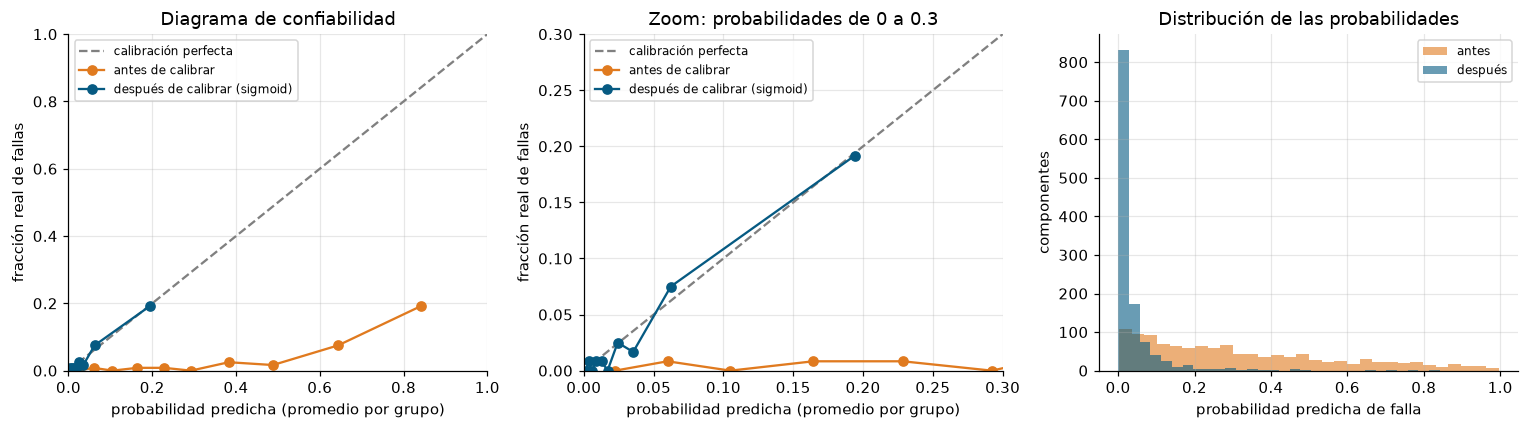

Cada punto agrupa 120 componentes de la prueba (grupos del mismo tamaño):
   prob. predicha antes  fallas reales (antes)  prob. predicha después  fallas reales (después)
0                 0.022                  0.000                   0.001                    0.000
1                 0.060                  0.008                   0.003                    0.008
2                 0.105                  0.000                   0.006                    0.000
3                 0.164                  0.008                   0.009                    0.008
4                 0.228                  0.008                   0.013                    0.008
5                 0.292                  0.000                   0.017                    0.000
6                 0.383                  0.025                   0.024                    0.025
7                 0.488                  0.017                   0.035                    0.017
8                 0.644                  0.075                

In [14]:
frac_antes, prob_antes = calibration_curve(y_test, proba_antes, n_bins=10, strategy="quantile")
frac_desp, prob_desp = calibration_curve(y_test, proba_despues, n_bins=10, strategy="quantile")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, lim, titulo in [(axes[0], 1.0, "Diagrama de confiabilidad"), (axes[1], 0.3, "Zoom: probabilidades de 0 a 0.3")]:
    ax.plot([0, lim], [0, lim], "--", color="gray", label="calibración perfecta")
    ax.plot(prob_antes, frac_antes, "o-", color="#E07A1F", label="antes de calibrar")
    ax.plot(prob_desp, frac_desp, "o-", color="#065A82", label="después de calibrar (sigmoid)")
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_xlabel("probabilidad predicha (promedio por grupo)"); ax.set_ylabel("fracción real de fallas")
    ax.set_title(titulo); ax.legend(fontsize=8)
axes[2].hist(proba_antes, bins=30, alpha=0.6, color="#E07A1F", label="antes")
axes[2].hist(proba_despues, bins=30, alpha=0.6, color="#065A82", label="después")
axes[2].set_xlabel("probabilidad predicha de falla"); axes[2].set_ylabel("componentes")
axes[2].set_title("Distribución de las probabilidades"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

print("Cada punto agrupa 120 componentes de la prueba (grupos del mismo tamaño):")
print(pd.DataFrame({"prob. predicha antes": prob_antes.round(3), "fallas reales (antes)": frac_antes.round(3),
                    "prob. predicha después": prob_desp.round(3), "fallas reales (después)": frac_desp.round(3)}).to_string())

**Interpretación.** Antes de calibrar, las probabilidades del modelo están muy **exageradas**. En promedio predice un **32 %** de probabilidad de falla, cuando la tasa real es de apenas **3.3 %**. En el diagrama de confiabilidad, la curva naranja queda muy por debajo de la diagonal: en el grupo donde el modelo predice en promedio **84 %** de riesgo, en realidad solo falla el **19 %** de los componentes. Esto no es un error del modelo, sino una consecuencia esperada de entrenarlo como si las fallas fueran tan frecuentes como los casos sanos.

Después de calibrar, la curva azul queda **prácticamente sobre la diagonal**: la probabilidad media predicha baja a **3.7 %**, muy cerca del 3.3 % real, y en el grupo de mayor riesgo el modelo predice **19 %** cuando la tasa real también es **19 %**. El **Brier score**, que mide qué tan lejos están las probabilidades de lo que realmente ocurrió (menor es mejor), baja de **0.155 a 0.029**, una reducción de alrededor del **81 %**. Las probabilidades calibradas ya pueden leerse como riesgos reales; por ejemplo, para priorizar qué componentes revisar primero. Como referencia, el modelo base tiene un Brier parecido (0.026), porque aprendió con la proporción real de fallas; la diferencia es que el base casi no detecta fallas, mientras que el modelo calibrado conserva la capacidad de detección de `class_weight="balanced"` y además da probabilidades realistas.

**Un detalle importante.** La calibración corrige las probabilidades, pero **no cambia el orden** en que el modelo clasifica a los componentes de más a menos riesgo. Lo que sí cambia es el significado del umbral: como ahora casi ninguna probabilidad supera 0.5, usar el umbral de siempre (0.5) haría que el modelo casi nunca alertara una falla. Si se usa el modelo calibrado para decidir, conviene fijar un umbral más bajo, elegido con validación cruzada según el costo de una falsa alarma frente al de una falla no detectada. Por eso, para **clasificar** se recomienda el modelo con `class_weight="balanced"`, y para **estimar el riesgo** de cada componente, su versión calibrada.

## Conclusión

La exactitud es engañosa en este problema: un modelo que nunca predice fallas obtiene 96.7 %. Con métricas adecuadas (MCC y kappa) se ve que el modelo base apenas detecta fallas (3 de 40), y que cualquiera de las cuatro estrategias contra el desbalance mejora mucho el resultado: detectan entre 32 y 33 fallas y elevan el MCC de prueba de 0.169 a alrededor de 0.25. Como las cuatro rinden prácticamente igual, se recomienda `class_weight="balanced"` por tener el mejor MCC en validación cruzada y ser la más sencilla. Finalmente, la calibración con `sigmoid` corrige las probabilidades infladas por el tratamiento del desbalance y reduce el Brier score en ~81 %, de modo que el modelo no solo identifica componentes en riesgo, sino que también estima ese riesgo de forma confiable.